# 07 · From strategy to QIS index

**Who this is for:** QIS structurers and index providers. A strategy becomes an index once its rules, costs and risk control are fixed and its level can be calculated by a third party. This notebook:

1. computes an **excess-return index** with replication costs, an index fee and an optional **volatility target**;
2. derives a **total-return** version from a cash rate;
3. builds a factsheet by calendar year and compares the sleeve with, and blends it into, classic factor indices;
4. generates a **rulebook** from the exact parameters.

In [1]:
# fmflow-setup: runs as-is everywhere. In an installed environment it only locates the repository; on Google Colab,
# Binder or a Jupyter without the package, it downloads the repository once and installs it (about a minute).
import importlib, importlib.util, os, shutil, subprocess, sys
from pathlib import Path

REPO_URL = os.environ.get("FMFLOW_REPO_URL", "https://github.com/bahakh19/first-mover-flow")   # set it to use a fork


def _run(cmd: list, what: str, hint: str = "") -> None:
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(f"{what} failed:\n{(r.stderr or r.stdout).strip()[-1500:]}\n{hint}")


_here = Path.cwd()
_root = next((p for p in (_here, *_here.parents, _here / "first-mover-flow") if (p / "src" / "fmflow").is_dir()), None)
if _root is None:                                                  # notebooks need the repository's data/ folder
    _root = (_here / "first-mover-flow").resolve()
    print(f"Downloading {REPO_URL} ...")
    if shutil.which("git"):
        _run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(_root)], f"git clone {REPO_URL}",
             "Is the repository public? For a fork or a local copy, set the environment variable FMFLOW_REPO_URL.")
    else:                                                          # no git: the GitHub zip archive of the main branch
        import io, urllib.request, zipfile
        with urllib.request.urlopen(REPO_URL.rstrip("/") + "/archive/refs/heads/main.zip") as _r:
            zipfile.ZipFile(io.BytesIO(_r.read())).extractall(_here)
        (_here / (REPO_URL.rstrip("/").split("/")[-1] + "-main")).rename(_root)
if importlib.util.find_spec("fmflow") is None:
    print("Installing fmflow and its dependencies (about a minute) ...")
    _target = f"{_root}[plot]"
    if importlib.util.find_spec("pip"):
        _run([sys.executable, "-m", "pip", "install", "-q", "-e", _target], "pip install")
    elif shutil.which("uv"):                                       # uv-created environments have no pip
        _run(["uv", "pip", "install", "-q", "--python", sys.executable, "-e", _target], "uv pip install")
    else:
        raise RuntimeError("this kernel has neither pip nor uv: install the package from a terminal (INSTALL.md)")
    sys.path.insert(0, str(_root / "src"))
    importlib.invalidate_caches()
os.chdir(_root / "notebooks")
print("fmflow", importlib.import_module("fmflow").__version__, "| repository:", _root)

fmflow 2.2.4 | repository: /home/claude/work/v22/repo


In [2]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from fmflow import StrategyConfig, load_prices, load_ratings, run_strategy
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE, GREEN, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#9a9a9a"
P = load_prices(ROOT / "data/open/MarketData_Normalized.csv")
R = load_ratings(ROOT / "data/open/Ratings_Normalized.csv", P)
SIG = pd.read_csv(ROOT / "tests/fixtures/open_sig_gjr.csv.gz", index_col=0, parse_dates=True)   # cached GARCH forecasts
EV = slice("2024-01-05", "2026-08-05")                                                          # pre-registered window
CFG = StrategyConfig.fmf_n_scalable()                                                           # leg fraction 0.4
out = run_strategy(P, R, CFG, sig_vol=SIG)
print(f"{out.prices.shape[1]} stocks, {len(out.prices)} sessions, {len(out.ratings):,} accepted ratings")
from fmflow.index import IndexRules, compute_index, index_factsheet, rulebook_markdown
from fmflow.benchmarks import comparable_books
from fmflow.analytics.metrics import perf_stats

30 stocks, 899 sessions, 2,363 accepted ratings


## 1. Excess-return index, with and without a volatility target

The leverage on day *t* is decided from realised volatility up to *t − 1*. Re-leveraging trades the whole book, so it pays the replication cost. A rebalance band avoids churning the leverage.

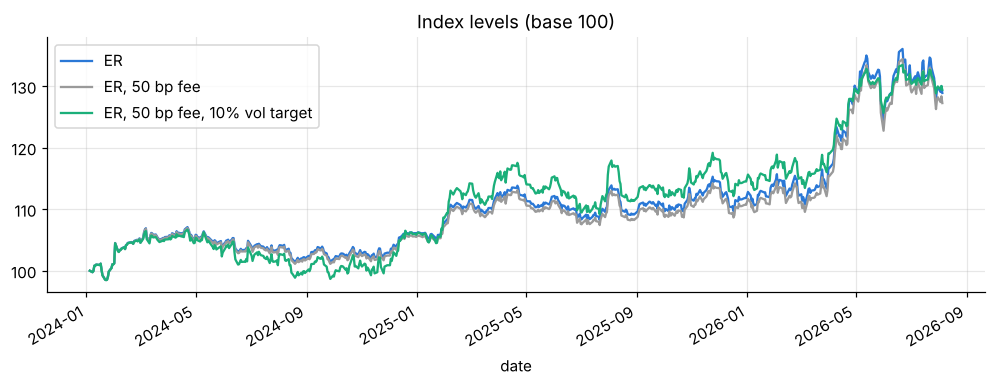

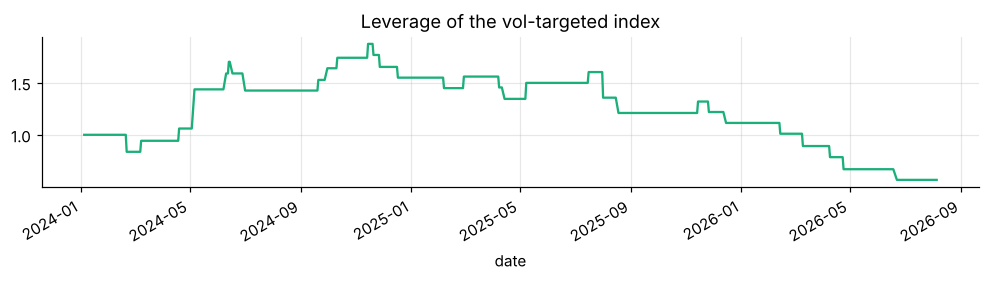

return   vol  Sharpe  max drawdown  \
ER                            2024          0.060 0.075   0.831        -0.053   
                              2025          0.055 0.077   0.739        -0.049   
                              2026          0.153 0.158   1.613        -0.080   
                              full period   0.104 0.101   1.035        -0.080   
ER, 50 bp fee                 2024          0.055 0.075   0.764        -0.054   
                              2025          0.050 0.077   0.674        -0.050   
                              2026          0.149 0.158   1.581        -0.080   
                              full period   0.099 0.101   0.986        -0.080   
ER, 50 bp fee, 10% vol target 2024          0.058 0.098   0.636        -0.075   
                              2025          0.082 0.106   0.799        -0.071   
                              2026          0.130 0.122   1.772        -0.054   
                              full period   0.106 0.107   0.994        -0.075   

                                           Calmar  
ER                            2024            NaN  
                              2025            NaN  
                              2026            NaN  
                              full period   1.305  
ER, 50 bp fee                 2024            NaN  
                              2025            NaN  
                              2026            NaN  
                              full period   1.232  
ER, 50 bp fee, 10% vol target 2024            NaN  
                              2025            NaN  
                              2026            NaN  
                              full period   1.408

In [3]:
base = "2024-01-05"
er = compute_index(out, IndexRules(name="FMF-N ER", base_date=base, fee_bps=0, replication_cost_bps=5))
er_fee = compute_index(out, IndexRules(name="FMF-N ER (50 bp fee)", base_date=base, fee_bps=50, replication_cost_bps=5))
vt = compute_index(out, IndexRules(name="FMF-N ER VT10", base_date=base, fee_bps=50, replication_cost_bps=5, vol_target=0.10,
                                    vol_lookback=63, max_leverage=2.0, rebalance_band=0.10))
levels = pd.DataFrame({"ER": er["level"], "ER, 50 bp fee": er_fee["level"], "ER, 50 bp fee, 10% vol target": vt["level"]})
levels.plot(figsize=(11, 3.4), color=[BLUE, GREY, GREEN], title="Index levels (base 100)"); plt.show()
vt["leverage"].plot(figsize=(11, 2), color=GREEN, title="Leverage of the vol-targeted index"); plt.show()
display(pd.concat({k: index_factsheet(levels[k]) for k in levels}, axis=0))

## 2. Total-return version

A self-financing long/short index earns the cash rate on its notional in a funded wrapper. The example uses a flat 3% rate. In production, pass the actual overnight-rate series.

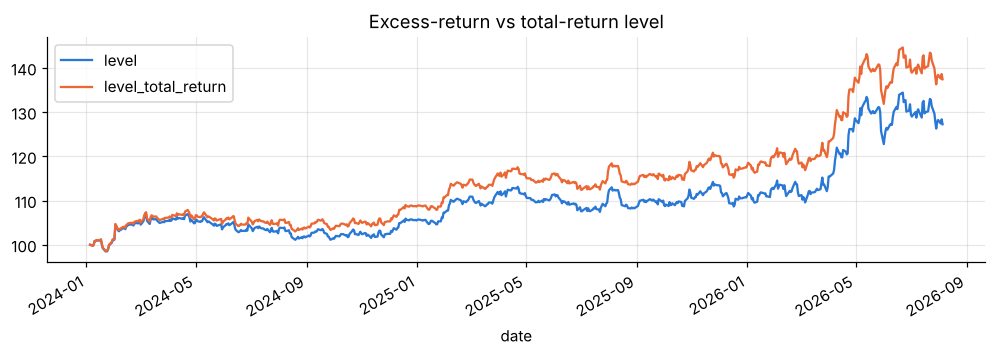

In [4]:
cash = pd.Series(0.03, index=out.prices.index)
tr = compute_index(out, IndexRules(name="FMF-N TR", base_date=base, fee_bps=50, cash_rate=cash))
tr[["level", "level_total_return"]].plot(figsize=(11, 3), color=[BLUE, ORANGE], title="Excess-return vs total-return level"); plt.show()

## 3. The sleeve inside a factor platform

QIS desks rarely sell a single sleeve. What matters is what FMF-N does to the indices clients already hold. Each comparable is run with the same construction and costs, then blended 50/50 with FMF-N.

,Sharpe alone,Sharpe 50/50,Calmar alone,Calmar 50/50,corr with FMF-N
Low analyst dispersion,-0.887,0.121,-0.330,0.065,-0.128
Betting-against-beta (low beta),-0.939,0.084,-0.322,0.028,-0.187
Low volatility (60d),-0.390,0.438,-0.171,0.282,0.121
Short-term reversal (1m),-0.137,0.839,-0.119,0.610,-0.413
Multi-factor: mom + low vol + reversal,-0.002,0.627,-0.014,0.481,0.388
Target-price upside (consensus),0.114,1.127,0.052,1.357,-0.470
52-week-high proximity,0.312,0.745,0.187,0.719,0.659
Residual momentum (Blitz et al.),0.561,0.882,0.541,1.016,0.659
12-1 momentum (Jegadeesh-Titman),0.596,0.915,0.619,1.077,0.608
6-1 momentum,0.563,0.891,0.627,1.067,0.630


50/50 blend raises the Calmar of 16 of 16 books


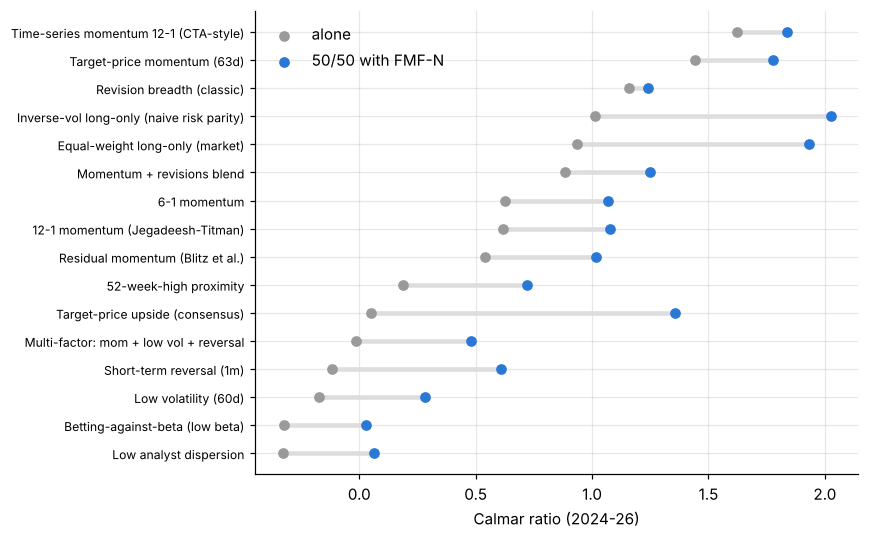

In [5]:
books = comparable_books(out)
f = out.net_returns.loc[EV]
rows = {}
for k, b in books.items():
    b = b.loc[EV]
    blend = 0.5 * f + 0.5 * (b / b.std() * f.std())
    rows[k] = {"Sharpe alone": perf_stats(b)["Sharpe"], "Sharpe 50/50": perf_stats(blend)["Sharpe"],
               "Calmar alone": perf_stats(b)["Calmar"], "Calmar 50/50": perf_stats(blend)["Calmar"], "corr with FMF-N": f.corr(b)}
bt = pd.DataFrame(rows).T.sort_values("Calmar alone")
display(bt)
print(f"50/50 blend raises the Calmar of {(bt['Calmar 50/50'] > bt['Calmar alone']).sum()} of {len(bt)} books")
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(bt))
ax.hlines(y, bt["Calmar alone"], bt["Calmar 50/50"], color="#dddddd", lw=3)
ax.scatter(bt["Calmar alone"], y, color=GREY, label="alone", zorder=3); ax.scatter(bt["Calmar 50/50"], y, color=BLUE, label="50/50 with FMF-N", zorder=3)
ax.set_yticks(y); ax.set_yticklabels(bt.index, fontsize=8); ax.legend(frameon=False); ax.set_xlabel("Calmar ratio (2024-26)"); plt.tight_layout(); plt.show()

## 4. Rulebook

The rulebook is generated from the exact parameters. It still needs legal text and calculation-agent provisions, but it can never drift from the code.

In [6]:
from IPython.display import Markdown
Markdown(rulebook_markdown(IndexRules(name="FMF-N Excess Return Index VT10", base_date=base, fee_bps=50, vol_target=0.10,
                                      max_leverage=2.0), out.config))

# FMF-N Excess Return Index VT10 -- Index Rulebook (generated)

1. **Universe.** All stocks in the price file with a valid composite score on the calculation date.
2. **Signals.** breadth_63, event_breadth_63, breadth_resid_mom, leader_minus_herd. Each is ranked cross-sectionally; the composite is the equal-weight mean of available ranks.
   Analyst data are used from the session after publication; targets expire after 252 sessions.
3. **Selection.** Long the highest-ranked and short the lowest-ranked 40% of the names with a valid score per leg.
4. **Weighting.** Inverse GJR-GARCH-t volatility weights within each leg;
   net exposure +0.00; dollar-neutral legs.
5. **Rebalancing.** Daily, in 42 overlapping tranches (1/42 of the book is re-targeted each day).
6. **Costs.** Replication cost 5 bp per unit traded; short borrow 0 bp p.a.;
   index fee 50 bp p.a. accrued daily.
7. **Risk control.** Volatility target 10% using 63-day realised volatility, leverage capped at 2.00x and decided with a one-day lag.
8. **Index level.** Base 100 on 2024-01-05; excess-return
   construction (self-financing long/short).
